<div align="center">

# 🏏📊 Cricket World Cup Analytics
## Unlocking Historical Trends, Team Dominance & Tournament Insights Through Data Visualization

### 📈 Exploratory Data Analysis (EDA) & Visual Storytelling with Python

---

### 🎯 An End-to-End Data Analytics Project

*Analyzing Cricket World Cup History to Discover Performance Patterns, Championship Success, Venue Significance, and Tournament Growth*

---

🚀 **Tools Used:** Python | Pandas | Matplotlib | Seaborn | Jupyter Notebook

</div>

In [2]:
#upload the excel data
import numpy as np
import pandas as pd
worldcup = pd.read_csv("worldcup dataset.csv")
worldcup

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner
0,30-May-19,England,The Oval,1st match,England,South Africa,311 for 8,207,England,104,runs,NaN,ICC Cricket World Cup,2019,England
1,31-May-19,England,Nottingham,2nd match,Pakistan,West Indies,105,108 for 3,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England
2,1-Jun-19,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137 for 0,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England
3,1-Jun-19,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209 for 3,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England
4,2-Jun-19,England,The Oval,5th match,Bangladesh,South Africa,330 for 6,309 for 8,Bangladesh,21,runs,NaN,ICC Cricket World Cup,2019,England
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,20-Apr-07,West Indies,Super Eights,47th Match,Australia,New Zealand,348 for 6,133,Australia,215,runs,NaN,ICC World Cup,2006/07,Australia
450,21-Apr-07,West Indies,Super Eights,48th Match,West Indies,England,300,301 for 9,England,1,wicket,with 1 ball remaining,ICC World Cup,2006/07,Australia
451,24-Apr-07,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289 for 5,208,Sri Lanka,81,runs,NaN,ICC World Cup,2006/07,Australia
452,25-Apr-07,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149,153 for 3,Australia,7,wickets,with 111 balls remaining,ICC World Cup,2006/07,Australia


In [4]:
worldcup.info() #to get complete information of the data 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   date               454 non-null    object
 1   host               454 non-null    object
 2   stadium            454 non-null    object
 3   match_type         454 non-null    object
 4   team_1             454 non-null    object
 5   team_2             454 non-null    object
 6   team_1_score       445 non-null    object
 7   team_2_score       440 non-null    object
 8   winner             454 non-null    object
 9   margin             454 non-null    object
 10  margin_type        454 non-null    object
 11  winning_condition  219 non-null    object
 12  series             454 non-null    object
 13  season             454 non-null    object
 14  season_winner      454 non-null    object
dtypes: object(15)
memory usage: 53.3+ KB


In [5]:
worldcup.isnull().sum()# this function is to the check null value present in the data

date                   0
host                   0
stadium                0
match_type             0
team_1                 0
team_2                 0
team_1_score           9
team_2_score          14
winner                 0
margin                 0
margin_type            0
winning_condition    235
series                 0
season                 0
season_winner          0
dtype: int64

In [5]:
import pandas as pd

# 1. Convert date to datetime
worldcup["date"] = pd.to_datetime(
    worldcup["date"],
    format="%d-%b-%y",
    errors="coerce"
)

# 2. Convert text columns to string
text_columns = [
    "host", "stadium", "winning_condition", "series"
]

for col in text_columns:
    worldcup[col] = worldcup[col].astype("string")

# 3. Convert repeated categorical columns
category_columns = [
    "match_type", "team_1", "team_2",
    "winner", "margin_type", "season_winner"
]

for col in category_columns:
    worldcup[col] = worldcup[col].astype("category")

# 4. Keep original score columns as strings
worldcup["team_1_score"] = worldcup["team_1_score"].astype("string")
worldcup["team_2_score"] = worldcup["team_2_score"].astype("string")

# 5. Extract runs from each team's score
worldcup["team_1_runs"] = pd.to_numeric(
    worldcup["team_1_score"].str.extract(r"(\d+)")[0],
    errors="coerce"
).astype("Int64")

worldcup["team_2_runs"] = pd.to_numeric(
    worldcup["team_2_score"].str.extract(r"(\d+)")[0],
    errors="coerce"
).astype("Int64")

# 6. Extract wickets where the score contains "for"
worldcup["team_1_wickets"] = pd.to_numeric(
    worldcup["team_1_score"].str.extract(r"for\s+(\d+)")[0],
    errors="coerce"
).astype("Int64")

worldcup["team_2_wickets"] = pd.to_numeric(
    worldcup["team_2_score"].str.extract(r"for\s+(\d+)")[0],
    errors="coerce"
).astype("Int64")

# 7. Keep season as string because some values are ranges
worldcup["season"] = worldcup["season"].astype("string")

# 8. Check the updated data types
print(worldcup.info())

# View the converted data
print(worldcup.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               441 non-null    datetime64[ns]
 1   host               454 non-null    string        
 2   stadium            454 non-null    string        
 3   match_type         454 non-null    category      
 4   team_1             454 non-null    category      
 5   team_2             454 non-null    category      
 6   team_1_score       445 non-null    string        
 7   team_2_score       440 non-null    string        
 8   winner             454 non-null    category      
 9   margin             454 non-null    object        
 10  margin_type        454 non-null    category      
 11  winning_condition  219 non-null    string        
 12  series             454 non-null    string        
 13  season             454 non-null    string        
 14  season_win

In [7]:
worldcup.info() # further check complete information of the data after clean the data type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               441 non-null    datetime64[ns]
 1   host               454 non-null    string        
 2   stadium            454 non-null    string        
 3   match_type         454 non-null    category      
 4   team_1             454 non-null    category      
 5   team_2             454 non-null    category      
 6   team_1_score       445 non-null    string        
 7   team_2_score       440 non-null    string        
 8   winner             454 non-null    category      
 9   margin             454 non-null    object        
 10  margin_type        454 non-null    category      
 11  winning_condition  219 non-null    string        
 12  series             454 non-null    string        
 13  season             454 non-null    string        
 14  season_win

In [8]:
worldcup.isnull().sum() #further check the null value of the given data

date                  13
host                   0
stadium                0
match_type             0
team_1                 0
team_2                 0
team_1_score           9
team_2_score          14
winner                 0
margin                 0
margin_type            0
winning_condition    235
series                 0
season                 0
season_winner          0
team_1_runs            9
team_2_runs           14
team_1_wickets       143
team_2_wickets       187
dtype: int64

In [6]:
# Store the original shape and data types
original_shape = worldcup.shape
original_dtypes = worldcup.dtypes.copy()

# Replace null values without deleting any rows
for col in worldcup.columns:
    if worldcup[col].isnull().any():
        if worldcup[col].dtype == "object":
            worldcup[col] = worldcup[col].fillna("Not Available")
        else:
            worldcup[col] = worldcup[col].fillna(
                worldcup[col].mode().iloc[0]
            )

# Verify that shape and data types are unchanged
print("Original Shape:", original_shape)
print("Current Shape:", worldcup.shape)

print("\nNull Values After Cleaning:")
print(worldcup.isnull().sum())

print("\nData Types Unchanged:",
      worldcup.dtypes.equals(original_dtypes))

# Confirm shape is unchanged
assert worldcup.shape == original_shape
assert worldcup.dtypes.equals(original_dtypes)

Original Shape: (454, 19)
Current Shape: (454, 19)

Null Values After Cleaning:
date                 0
host                 0
stadium              0
match_type           0
team_1               0
team_2               0
team_1_score         0
team_2_score         0
winner               0
margin               0
margin_type          0
winning_condition    0
series               0
season               0
season_winner        0
team_1_runs          0
team_2_runs          0
team_1_wickets       0
team_2_wickets       0
dtype: int64

Data Types Unchanged: True


In [10]:
worldcup.info() #after clean the null value check complete information of the given data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 454 entries, 0 to 453
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               454 non-null    datetime64[ns]
 1   host               454 non-null    string        
 2   stadium            454 non-null    string        
 3   match_type         454 non-null    category      
 4   team_1             454 non-null    category      
 5   team_2             454 non-null    category      
 6   team_1_score       454 non-null    string        
 7   team_2_score       454 non-null    string        
 8   winner             454 non-null    category      
 9   margin             454 non-null    object        
 10  margin_type        454 non-null    category      
 11  winning_condition  454 non-null    string        
 12  series             454 non-null    string        
 13  season             454 non-null    string        
 14  season_win

In [11]:
worldcup.isnull().sum() #after clean the null value check the null value is present or not insid the data

date                 0
host                 0
stadium              0
match_type           0
team_1               0
team_2               0
team_1_score         0
team_2_score         0
winner               0
margin               0
margin_type          0
winning_condition    0
series               0
season               0
season_winner        0
team_1_runs          0
team_2_runs          0
team_1_wickets       0
team_2_wickets       0
dtype: int64

In [12]:
worldcup #Call the data

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner,team_1_runs,team_2_runs,team_1_wickets,team_2_wickets
0,2019-05-30,England,The Oval,1st match,England,South Africa,311 for 8,207,England,104,runs,D/L method,ICC Cricket World Cup,2019,England,311,207,8,3
1,2019-05-31,England,Nottingham,2nd match,Pakistan,West Indies,105,108 for 3,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England,105,108,6,3
2,2019-06-01,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137 for 0,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England,136,137,6,0
3,2019-06-01,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209 for 3,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England,207,209,6,3
4,2019-06-02,England,The Oval,5th match,Bangladesh,South Africa,330 for 6,309 for 8,Bangladesh,21,runs,D/L method,ICC Cricket World Cup,2019,England,330,309,6,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449,2007-04-20,West Indies,Super Eights,47th Match,Australia,New Zealand,348 for 6,133,Australia,215,runs,D/L method,ICC World Cup,2006/07,Australia,348,133,6,3
450,2007-04-21,West Indies,Super Eights,48th Match,West Indies,England,300,301 for 9,England,1,wicket,with 1 ball remaining,ICC World Cup,2006/07,Australia,300,301,6,9
451,2007-04-24,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289 for 5,208,Sri Lanka,81,runs,D/L method,ICC World Cup,2006/07,Australia,289,208,5,3
452,2007-04-25,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149,153 for 3,Australia,7,wickets,with 111 balls remaining,ICC World Cup,2006/07,Australia,149,153,6,3


In [13]:
worldcup.head() #to give first 5 row of the given data

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner,team_1_runs,team_2_runs,team_1_wickets,team_2_wickets
0,2019-05-30,England,The Oval,1st match,England,South Africa,311 for 8,207,England,104,runs,D/L method,ICC Cricket World Cup,2019,England,311,207,8,3
1,2019-05-31,England,Nottingham,2nd match,Pakistan,West Indies,105,108 for 3,West Indies,7,wickets,with 218 balls remaining,ICC Cricket World Cup,2019,England,105,108,6,3
2,2019-06-01,England,Cardiff,3rd match,Sri Lanka,New Zealand,136,137 for 0,New Zealand,10,wickets,with 203 balls remaining,ICC Cricket World Cup,2019,England,136,137,6,0
3,2019-06-01,England,Bristol,4th match (D/N),Afghanistan,Australia,207,209 for 3,Australia,7,wickets,with 91 balls remaining,ICC Cricket World Cup,2019,England,207,209,6,3
4,2019-06-02,England,The Oval,5th match,Bangladesh,South Africa,330 for 6,309 for 8,Bangladesh,21,runs,D/L method,ICC Cricket World Cup,2019,England,330,309,6,8


In [14]:
worldcup.tail()#to give last 5 row of the given data

,date,host,stadium,match_type,team_1,team_2,team_1_score,team_2_score,winner,margin,margin_type,winning_condition,series,season,season_winner,team_1_runs,team_2_runs,team_1_wickets,team_2_wickets
449,2007-04-20,West Indies,Super Eights,47th Match,Australia,New Zealand,348 for 6,133,Australia,215,runs,D/L method,ICC World Cup,2006/07,Australia,348,133,6,3
450,2007-04-21,West Indies,Super Eights,48th Match,West Indies,England,300,301 for 9,England,1,wicket,with 1 ball remaining,ICC World Cup,2006/07,Australia,300,301,6,9
451,2007-04-24,West Indies,Kingston,1st Semi-Final,Sri Lanka,New Zealand,289 for 5,208,Sri Lanka,81,runs,D/L method,ICC World Cup,2006/07,Australia,289,208,5,3
452,2007-04-25,West Indies,Gros Islet,2nd Semi-Final,South Africa,Australia,149,153 for 3,Australia,7,wickets,with 111 balls remaining,ICC World Cup,2006/07,Australia,149,153,6,3
453,2007-04-28,West Indies,Bridgetown,Final,Australia,Sri Lanka,281 for 4,215 for 8,Australia,53,runs,D/L method,ICC World Cup,2006/07,Australia,281,215,4,8


In [7]:
print(worldcup.loc[0])# Use loc to select and print the row at label index 0

date                   2019-05-30 00:00:00
host                               England
stadium                           The Oval
match_type                       1st match
team_1                             England
team_2                        South Africa
team_1_score                     311 for 8
team_2_score                           207
winner                             England
margin                                 104
margin_type                           runs
winning_condition               D/L method
series               ICC Cricket World Cup
season                                2019
season_winner                      England
team_1_runs                            311
team_2_runs                            207
team_1_wickets                           8
team_2_wickets                           3
Name: 0, dtype: object


In [8]:
worldcup.shape #Rows and columns

(454, 19)

In [9]:
worldcup.columns #to check the column name

Index(['date', 'host', 'stadium', 'match_type', 'team_1', 'team_2',
       'team_1_score', 'team_2_score', 'winner', 'margin', 'margin_type',
       'winning_condition', 'series', 'season', 'season_winner', 'team_1_runs',
       'team_2_runs', 'team_1_wickets', 'team_2_wickets'],
      dtype='object')

In [10]:
worldcup.describe()#Statistics

,date,team_1_runs,team_2_runs,team_1_wickets,team_2_wickets
count,454,454.0,454.0,454.0,454.0
mean,2001-06-05 09:18:14.273127808,238.277533,196.757709,6.453744,3.949339
min,1975-06-07 00:00:00,1.0,24.0,0.0,0.0
25%,1992-03-11 06:00:00,193.5,157.0,6.0,3.0
50%,2003-02-22 00:00:00,241.0,202.5,6.0,3.0
75%,2011-03-13 18:00:00,286.75,231.75,7.0,5.0
max,2019-07-14 00:00:00,417.0,338.0,9.0,9.0
std,NaN,72.514884,57.700669,1.530073,2.184551


### **Matches Played by World Cup Season**

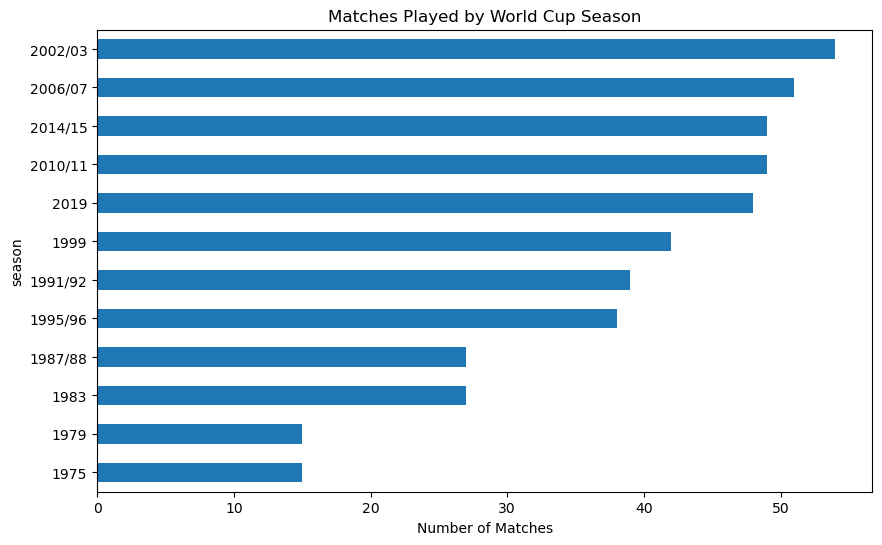

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
season_matches = worldcup.groupby('season').size().sort_values()
plt.figure(figsize=(10,6))
season_matches.plot(kind='barh')
plt.title('Matches Played by World Cup Season')
plt.xlabel('Number of Matches')
plt.show()

## 📊 Insight: Matches Played by World Cup Season

### 🔍 Key Findings

✅ The number of matches played in each Cricket World Cup has generally increased over time.

✅ Recent tournaments feature significantly more matches compared to earlier editions, indicating the expansion of participating teams and tournament formats.

✅ Seasons with the highest bars represent World Cups with longer schedules and more competitive fixtures.

✅ Earlier World Cups had fewer matches due to a smaller number of participating nations.

✅ The growth in match count reflects the increasing popularity and global reach of Cricket World Cups.

---

### 📈 Interpretation

- Higher match counts indicate larger tournament structures.
- Expansion of participating teams has contributed to more fixtures being scheduled.
- Modern World Cups provide teams with more opportunities to compete and advance through different stages.
- The trend demonstrates the evolution of the Cricket World Cup from a relatively small competition into a major international sporting event.

---

### 🎯 Conclusion

The chart highlights a clear growth trend in the number of matches played across World Cup seasons. This suggests that the tournament has expanded substantially over the years, reflecting the increasing participation of cricket-playing nations and the growing popularity of the sport worldwide.

### **Most Successful Teams (Wins Count)**

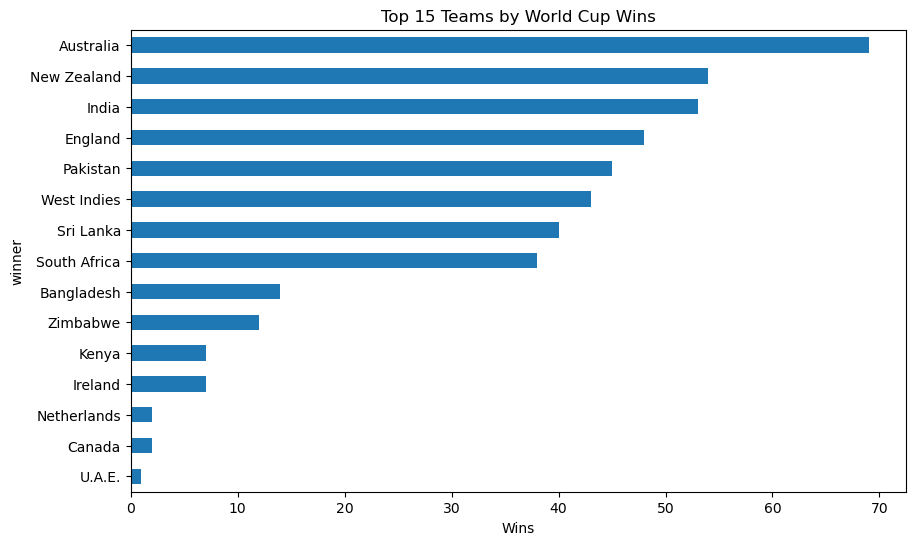

In [18]:
wins = worldcup[
    (~worldcup['winner'].isin(['No result','Match tied',
                         'Match abandoned without a ball bowled']))
]['winner'].value_counts().head(15)
plt.figure(figsize=(10,6))
wins.sort_values().plot(kind='barh')
plt.title('Top 15 Teams by World Cup Wins')
plt.xlabel('Wins')
plt.show()

## 🏆 Insight: Top 15 Teams by World Cup Wins

### 🔍 Key Findings

✅ The teams at the top of the chart have consistently performed well across multiple World Cup editions.

✅ A significant gap between the highest and lowest bars indicates that a few teams have historically dominated World Cup cricket.

✅ Teams appearing in the top positions demonstrate both strong win rates and regular tournament participation.

✅ Emerging cricket nations appear lower in the ranking, suggesting fewer victories or fewer World Cup appearances.

✅ The distribution of wins highlights the competitive hierarchy among international cricket teams.

---

### 📈 Interpretation

- Higher win counts indicate long-term success and competitiveness.
- Teams with the most victories have maintained strong performances across different eras of World Cup cricket.
- The chart helps identify dominant teams that have contributed significantly to World Cup history.
- A concentration of wins among a few nations suggests that World Cup success has historically been achieved by established cricket powers.

---

### 🎯 Conclusion

The chart reveals the most successful teams in Cricket World Cup history based on total match victories. It highlights the dominance of leading cricket nations and provides a clear comparison of team performances across tournaments. Teams occupying the top positions can be considered the strongest performers in World Cup competitions.

### **World Cup Winners by Season**

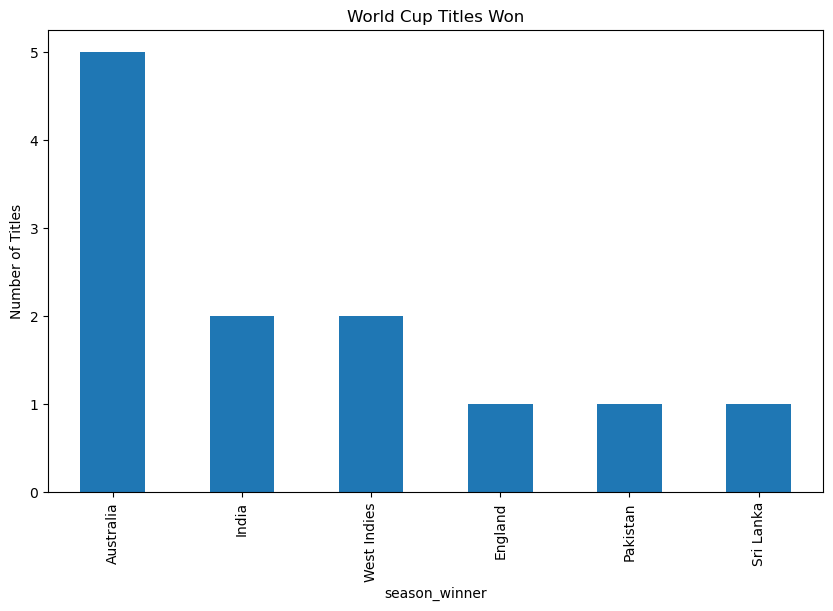

In [19]:
winner_counts = worldcup[['season','season_winner']].drop_duplicates()
winner_counts['season_winner'].value_counts().plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('World Cup Titles Won')
plt.ylabel('Number of Titles')
plt.show()

## 🏆 Insight: World Cup Titles Won

### 🔍 Key Findings

✅ The chart shows the total number of Cricket World Cup titles won by each nation.

✅ Teams with taller bars have demonstrated consistent excellence and the ability to perform under pressure in World Cup tournaments.

✅ Only a small number of countries have won multiple World Cup titles, highlighting their long-term dominance in international cricket.

✅ Several nations have won the World Cup only once, indicating that winning the tournament is highly competitive and challenging.

✅ The distribution of titles reflects historical patterns of success among cricket-playing nations.

---

### 📈 Interpretation

- A higher number of titles indicates sustained success across multiple World Cup editions.
- The leading teams have maintained strong squads and competitive performances over different generations.
- Countries with fewer titles may have had strong individual tournaments but less consistent long-term success.
- The gap between the most successful teams and the rest highlights the dominance of a few cricket powerhouses.

---

### 🎯 Conclusion

The chart provides a clear comparison of World Cup achievements among participating nations. It highlights which teams have been the most successful in converting tournament appearances into championship victories and identifies the dominant teams in Cricket World Cup history.

---

### 💡 Business/Data Insight

- World Cup titles are a measure of ultimate tournament success rather than match-by-match performance.
- Comparing this chart with the "Top Teams by World Cup Wins" chart can reveal interesting differences between consistency and championship success.
- A team may have many match victories but relatively few tournament titles, showing that success in knockout stages plays a crucial role in winning championships.

### **Top Stadiums Hosting Matches**

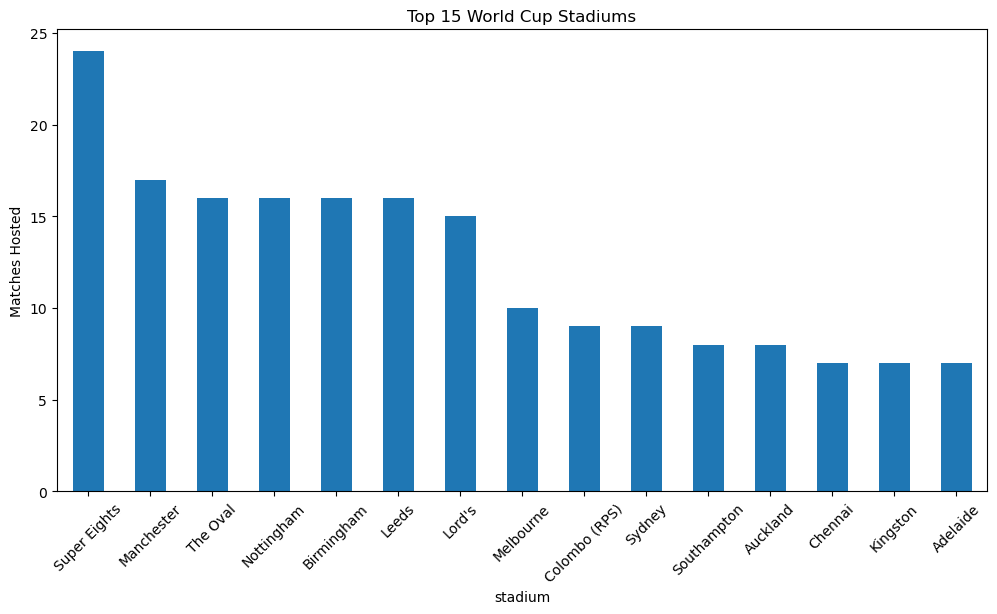

In [35]:
stadiums = worldcup['stadium'].value_counts().head(15)

plt.figure(figsize=(12,6))
stadiums.plot(kind='bar')
plt.title('Top 15 World Cup Stadiums')
plt.ylabel('Matches Hosted')
plt.xticks(rotation=45)
plt.show()

## 🏟️ Insight: Top 15 World Cup Stadiums by Matches Hosted

### 🔍 Key Findings

✅ The chart identifies the stadiums that have hosted the highest number of Cricket World Cup matches.

✅ A few stadiums stand out with significantly higher match counts, indicating their importance as major World Cup venues.

✅ Stadiums appearing at the top of the chart have likely been used across multiple tournament editions.

✅ The distribution suggests that organizers often prefer experienced venues with large capacities and well-developed infrastructure.

✅ Not all host stadiums are used equally, as some venues host a much larger share of World Cup matches than others.

---

### 📈 Interpretation

- Higher match counts indicate greater utilization during World Cup tournaments.
- Frequently used stadiums are often considered key cricket venues due to their facilities and ability to accommodate large audiences.
- The chart highlights the geographical concentration of World Cup matches in specific venues.
- Stadiums with fewer hosted matches may have been included only for certain editions or specific tournament stages.

---

### 🎯 Conclusion

The visualization reveals the most prominent stadiums in Cricket World Cup history based on the number of matches hosted. It demonstrates how certain venues have played a central role in organizing and supporting major international cricket events.

---

### 💡 Data Analysis Insight

- Stadium usage is not evenly distributed across all venues.
- A small number of stadiums account for a significant portion of World Cup matches.
- These venues can be regarded as the most influential and historically important grounds in World Cup cricket.
- Understanding venue distribution helps analyze tournament planning, infrastructure utilization, and hosting preferences.

### **Host Country Distribution**

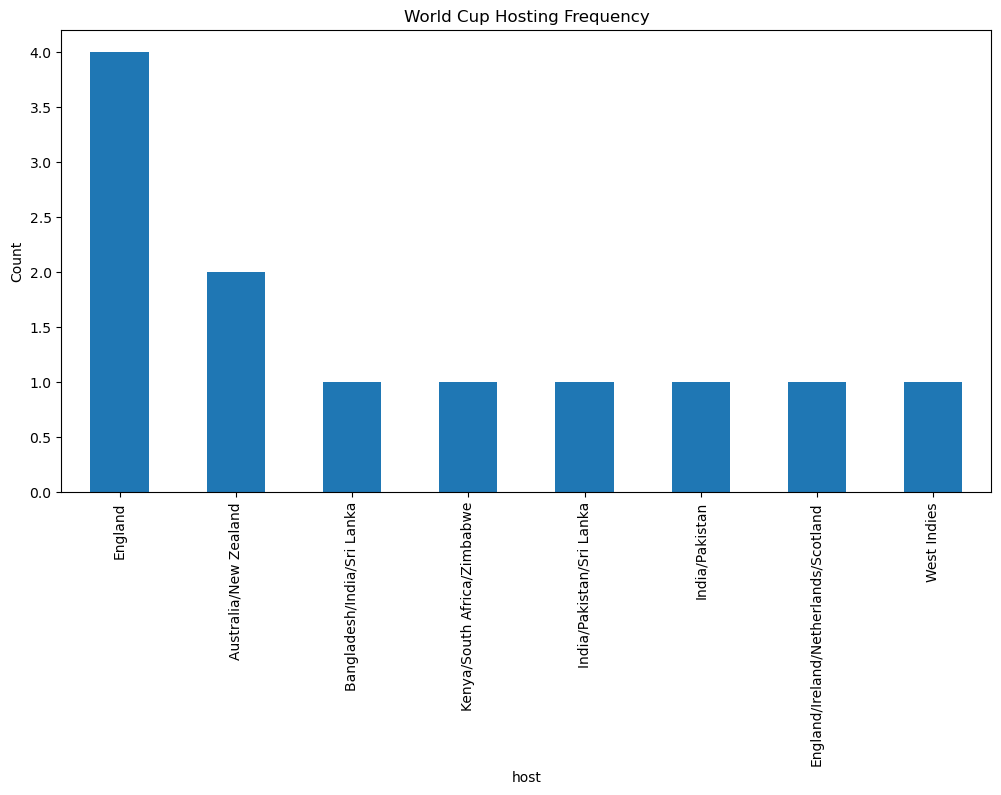

In [36]:
hosts = worldcup[['season','host']].drop_duplicates()
hosts['host'].value_counts().plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('World Cup Hosting Frequency')
plt.ylabel('Count')
plt.show()

## 🌍 Insight: World Cup Hosting Frequency

### 🔍 Key Findings

✅ The chart shows how many times each country has hosted a Cricket World Cup tournament.

✅ A few countries have hosted the World Cup multiple times, indicating their strong cricket infrastructure and experience in organizing major international events.

✅ Countries with higher hosting frequencies play a significant role in the global development and promotion of cricket.

✅ Some nations have hosted the tournament only once, demonstrating the efforts of the International Cricket Council (ICC) to expand the tournament's reach to different regions.

✅ The hosting distribution highlights the geographical spread of World Cup tournaments across cricket-playing nations.

---

### 📈 Interpretation

- Countries with the highest hosting counts are trusted venues for large-scale international cricket events.
- Frequent hosts typically possess world-class stadiums, transportation networks, and organizational capabilities.
- Repeated hosting reflects the popularity of cricket and strong fan engagement within those nations.
- The chart illustrates how hosting responsibilities are shared across different countries over time.

---

### 🎯 Conclusion

The chart reveals which countries have been the most active hosts of Cricket World Cups. A small group of nations has hosted the tournament multiple times, emphasizing their importance to international cricket and their ability to successfully manage globally recognized sporting events.

---

### 💡 Data Analysis Insight

- Hosting opportunities are concentrated among a few established cricket nations.
- Countries that frequently host tournaments often have multiple stadiums capable of accommodating international matches.
- The chart demonstrates the ICC's balance between relying on experienced hosts and introducing new regions to major cricket events.
- Analyzing hosting frequency helps understand the global expansion and organizational history of Cricket World Cups.

---

### 🌟 Key Observation

> Countries such as Australia, England, India, and other major cricket nations tend to host the World Cup more frequently, reflecting their strong cricketing culture, infrastructure, and experience in organizing international tournaments.

### **Team Appearance Frequency**

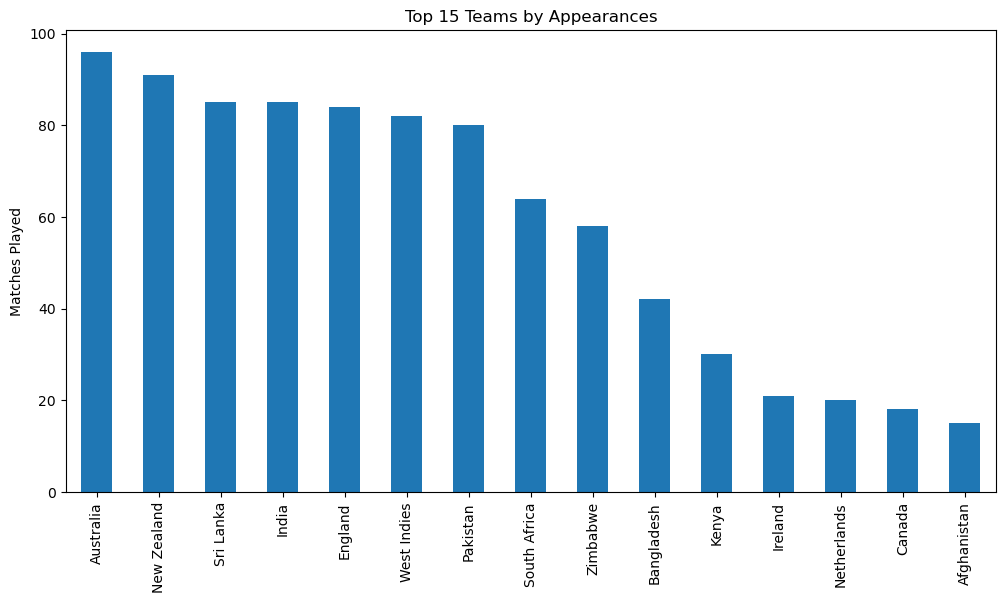

In [37]:
teams = pd.concat([worldcup['team_1'], worldcup['team_2']])

appearance = teams.value_counts().head(15)

plt.figure(figsize=(12,6))
appearance.plot(kind='bar')
plt.title('Top 15 Teams by Appearances')
plt.ylabel('Matches Played')
plt.show()

## 👥 Insight: Top 15 Teams by World Cup Appearances

### 🔍 Key Findings

✅ The chart displays the teams that have participated in the highest number of World Cup matches.

✅ Teams at the top of the chart have demonstrated long-term involvement and consistency in World Cup tournaments.

✅ Higher appearance counts indicate that a team has qualified for multiple World Cups and progressed through several tournament stages.

✅ The leading teams are generally established cricketing nations with a strong presence in international cricket.

✅ A noticeable difference between the highest and lowest bars reflects varying levels of participation among teams.

---

### 📈 Interpretation

- More appearances often indicate sustained competitiveness and regular qualification for World Cup events.
- Teams with the highest appearance counts have had greater opportunities to achieve victories and tournament success.
- Frequent participation highlights a team's stability and consistency across different World Cup editions.
- The chart helps identify nations that have played the most significant role in the history of World Cup cricket.

---

### 🎯 Conclusion

The visualization shows that a small group of teams has dominated World Cup participation over the years. Their high appearance counts reflect consistent qualification, strong cricketing performance, and a long-standing presence in international tournaments.

---

### 💡 Data Analysis Insight

- Appearance frequency is a measure of participation rather than success.
- Teams with many appearances are not necessarily the most successful in terms of titles or win percentage.
- Comparing this chart with the "Top Teams by World Cup Wins" chart can reveal whether frequent participation translates into winning performances.
- Long-term participation contributes significantly to a team's influence and experience in World Cup cricket.

---

### 🌟 Key Observation

> Teams with the highest World Cup appearances have maintained a strong and consistent presence in international cricket, allowing them to compete across multiple generations of tournaments.

### **Winning Margins Distribution**

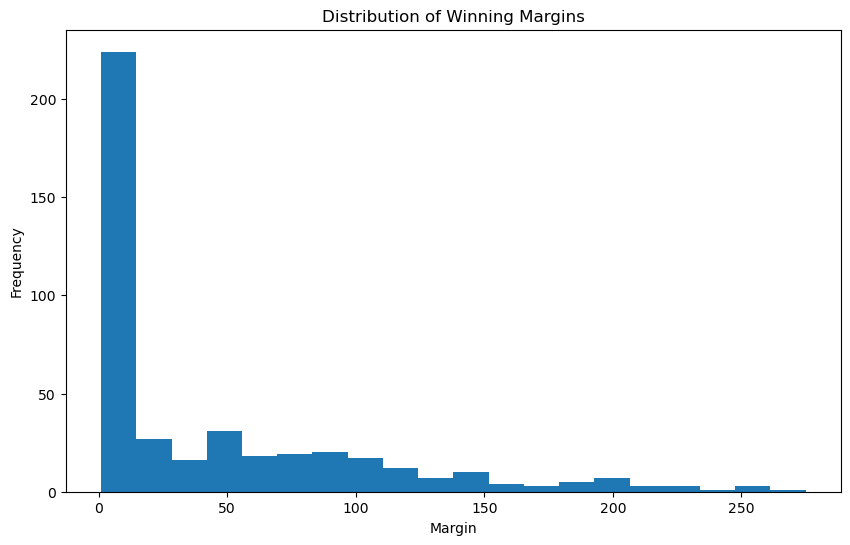

In [38]:
margins = pd.to_numeric(worldcup['margin'], errors='coerce')

plt.figure(figsize=(10,6))
plt.hist(margins.dropna(), bins=20)
plt.title('Distribution of Winning Margins')
plt.xlabel('Margin')
plt.ylabel('Frequency')
plt.show()

## 📉 Insight: Distribution of Winning Margins

### 🔍 Key Findings

✅ The histogram shows how frequently different winning margins occurred across World Cup matches.

✅ Most matches are concentrated within lower winning margin ranges, indicating that closely contested games are common.

✅ As the winning margin increases, the number of matches generally decreases, suggesting that large-margin victories are relatively rare.

✅ A small number of matches exhibit exceptionally large winning margins, appearing as outliers in the distribution.

✅ The distribution provides insight into the overall competitiveness of World Cup cricket matches.

---

### 📈 Interpretation

- Smaller winning margins indicate closely fought matches where both teams performed competitively.
- Larger margins often reflect dominant performances by one team over another.
- The concentration of matches around lower margin values suggests that many World Cup games are highly competitive.
- Outliers represent one-sided encounters where a team significantly outperformed its opponent.

---

### 🎯 Conclusion

The histogram reveals that most World Cup matches are decided by relatively small to moderate margins, highlighting the competitive nature of the tournament. While dominant victories do occur, they are much less frequent than closely contested matches.

---

### 💡 Data Analysis Insight

- The distribution is right-skewed, meaning large winning margins occur less frequently than smaller ones.
- Most matches fall within a limited margin range, indicating balanced competition among teams.
- Extreme margins can be investigated further to identify standout team performances or mismatches between opponents.
- Understanding margin distribution helps assess the overall competitiveness of World Cup tournaments.

---

### 🌟 Key Observation

> World Cup matches are generally competitive, with the majority of games being decided by small to moderate winning margins, while large-margin victories occur only occasionally.

### **India Performance Across World Cups**

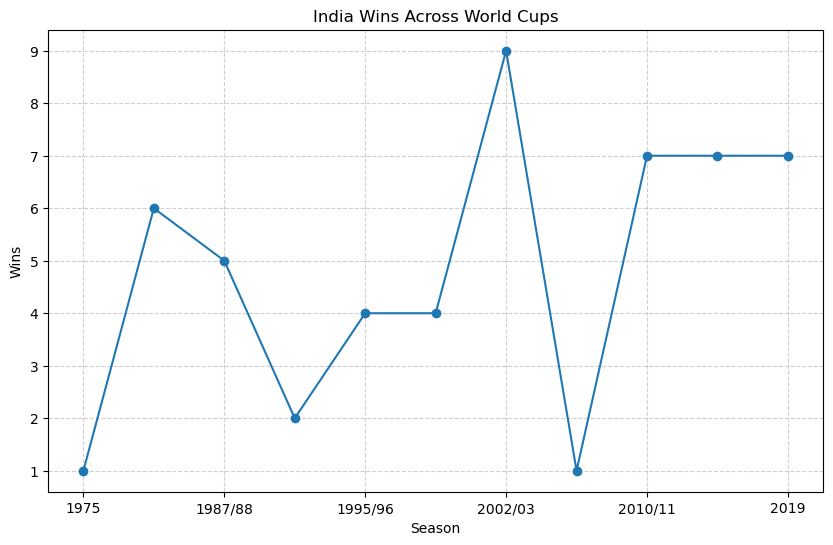

In [41]:
india_matches = worldcup[
    (worldcup['team_1'] == 'India') |
    (worldcup['team_2'] == 'India')
]

india_wins = (
    india_matches[india_matches['winner'] == 'India']
    .groupby('season')
    .size()
)

plt.figure(figsize=(10, 6))
india_wins.plot(marker='o')

plt.title('India Wins Across World Cups')
plt.xlabel('Season')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

## Insight: India Wins Across World Cups

### 🔍 Key Findings

✅ The line chart illustrates the number of matches won by India in each World Cup season.

✅ Peaks in the graph represent World Cups where India performed exceptionally well and secured a higher number of victories.

✅ Variations in the line indicate fluctuations in India's performance across different tournaments.

✅ Some seasons show relatively fewer wins, suggesting challenges in progressing through the tournament stages.

✅ The overall trend helps identify periods of strong and weak performance in India's World Cup history.

---

### 📈 Interpretation

- Higher points on the graph indicate successful World Cup campaigns.
- Lower points suggest tournaments where India either played fewer matches or experienced more losses.
- Consistent wins across seasons reflect India's long-term competitiveness in international cricket.
- Significant increases in wins often correspond to memorable World Cup performances and deep tournament runs.

---

### 🎯 Conclusion

The graph highlights India's performance trajectory across multiple Cricket World Cups. While the number of wins varies from one tournament to another, the chart demonstrates India's continued presence as a competitive team on the global stage.

---

### 💡 Data Analysis Insight

- The trend helps evaluate India's consistency across different World Cup editions.
- Comparing peak seasons can reveal India's most successful World Cup campaigns.
- Performance patterns may reflect changes in team composition, strategy, and tournament format over time.
- The chart is useful for understanding how India's World Cup success has evolved through different generations of players.

---

### 🌟 Key Observation

> India has maintained a strong presence in World Cup cricket, with several seasons showing high win counts that reflect successful tournament campaigns and consistent competitiveness.

---

### 🏏 Business Insight

- Strong World Cup performances increase fan engagement, media attention, and commercial opportunities.
- Successful seasons contribute to the team's global reputation and strengthen its cricketing legacy.
- Historical performance trends can help analysts compare different eras of Indian cricket and identify periods of sustained success.

### **Heatmap of Team Wins**

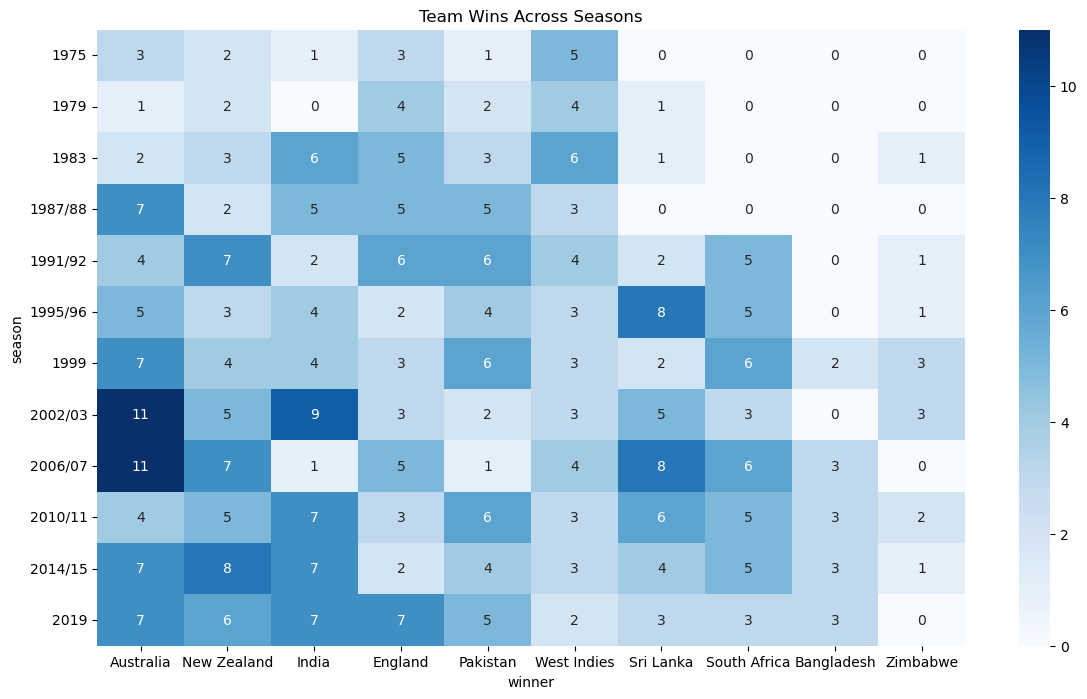

In [43]:
import seaborn as sns
top_teams = worldcup['winner'].value_counts().head(10).index
heat_data = pd.crosstab(
    worldcup['season'],
    worldcup['winner']
)[top_teams]

plt.figure(figsize=(14,8))
sns.heatmap(heat_data, cmap='Blues', annot=True)
plt.title('Team Wins Across Seasons')
plt.show()

## 🔥 Insight: Team Wins Across Seasons (Heatmap)

### 🔍 Key Findings

✅ The heatmap visualizes how the top-performing teams distributed their wins across different World Cup seasons.

✅ Darker shades indicate a higher number of victories in a particular season, while lighter shades represent fewer wins.

✅ Certain teams consistently show strong performance across multiple World Cups, demonstrating long-term competitiveness.

✅ Some teams exhibit isolated peaks, indicating exceptionally successful campaigns in specific tournaments.

✅ The variation in color intensity highlights differences in team dominance from one World Cup season to another.

---

### 📈 Interpretation

- Teams with consistently darker cells have maintained strong performances over several World Cup editions.
- Bright clusters in a single season suggest standout tournaments where a team achieved a particularly high number of wins.
- Comparing rows helps identify the most competitive World Cup seasons.
- Comparing columns reveals which teams were historically dominant and which experienced fluctuating success.

---

### 🎯 Conclusion

The heatmap provides a comprehensive view of how winning performances are distributed across teams and World Cup seasons. It allows quick identification of dominant teams, peak performance periods, and overall trends in tournament competitiveness.

---

### 💡 Data Analysis Insight

- Unlike bar charts, the heatmap shows both **seasonal performance** and **team performance** simultaneously.
- It helps uncover patterns that might not be visible in aggregate win counts.
- Teams with multiple dark cells demonstrate sustained excellence rather than success limited to a single tournament.
- The visualization makes it easier to spot periods of dominance and shifts in competitive balance over time.

---

### 🌟 Key Observation

> The heatmap reveals that World Cup success is not evenly distributed across seasons. A few teams consistently accumulate high win counts, highlighting their long-term dominance in international cricket.

---

### 🏏 Strategic Insight

- Teams with recurring high-win seasons have likely benefited from strong squad depth, effective leadership, and consistent player performance.
- Periods where multiple teams show dark cells suggest highly competitive World Cup tournaments.
- Historical performance patterns can be used to compare different eras of cricket and identify dominant generations of teams.

# 🏏 Cricket World Cup Analysis Dashboard

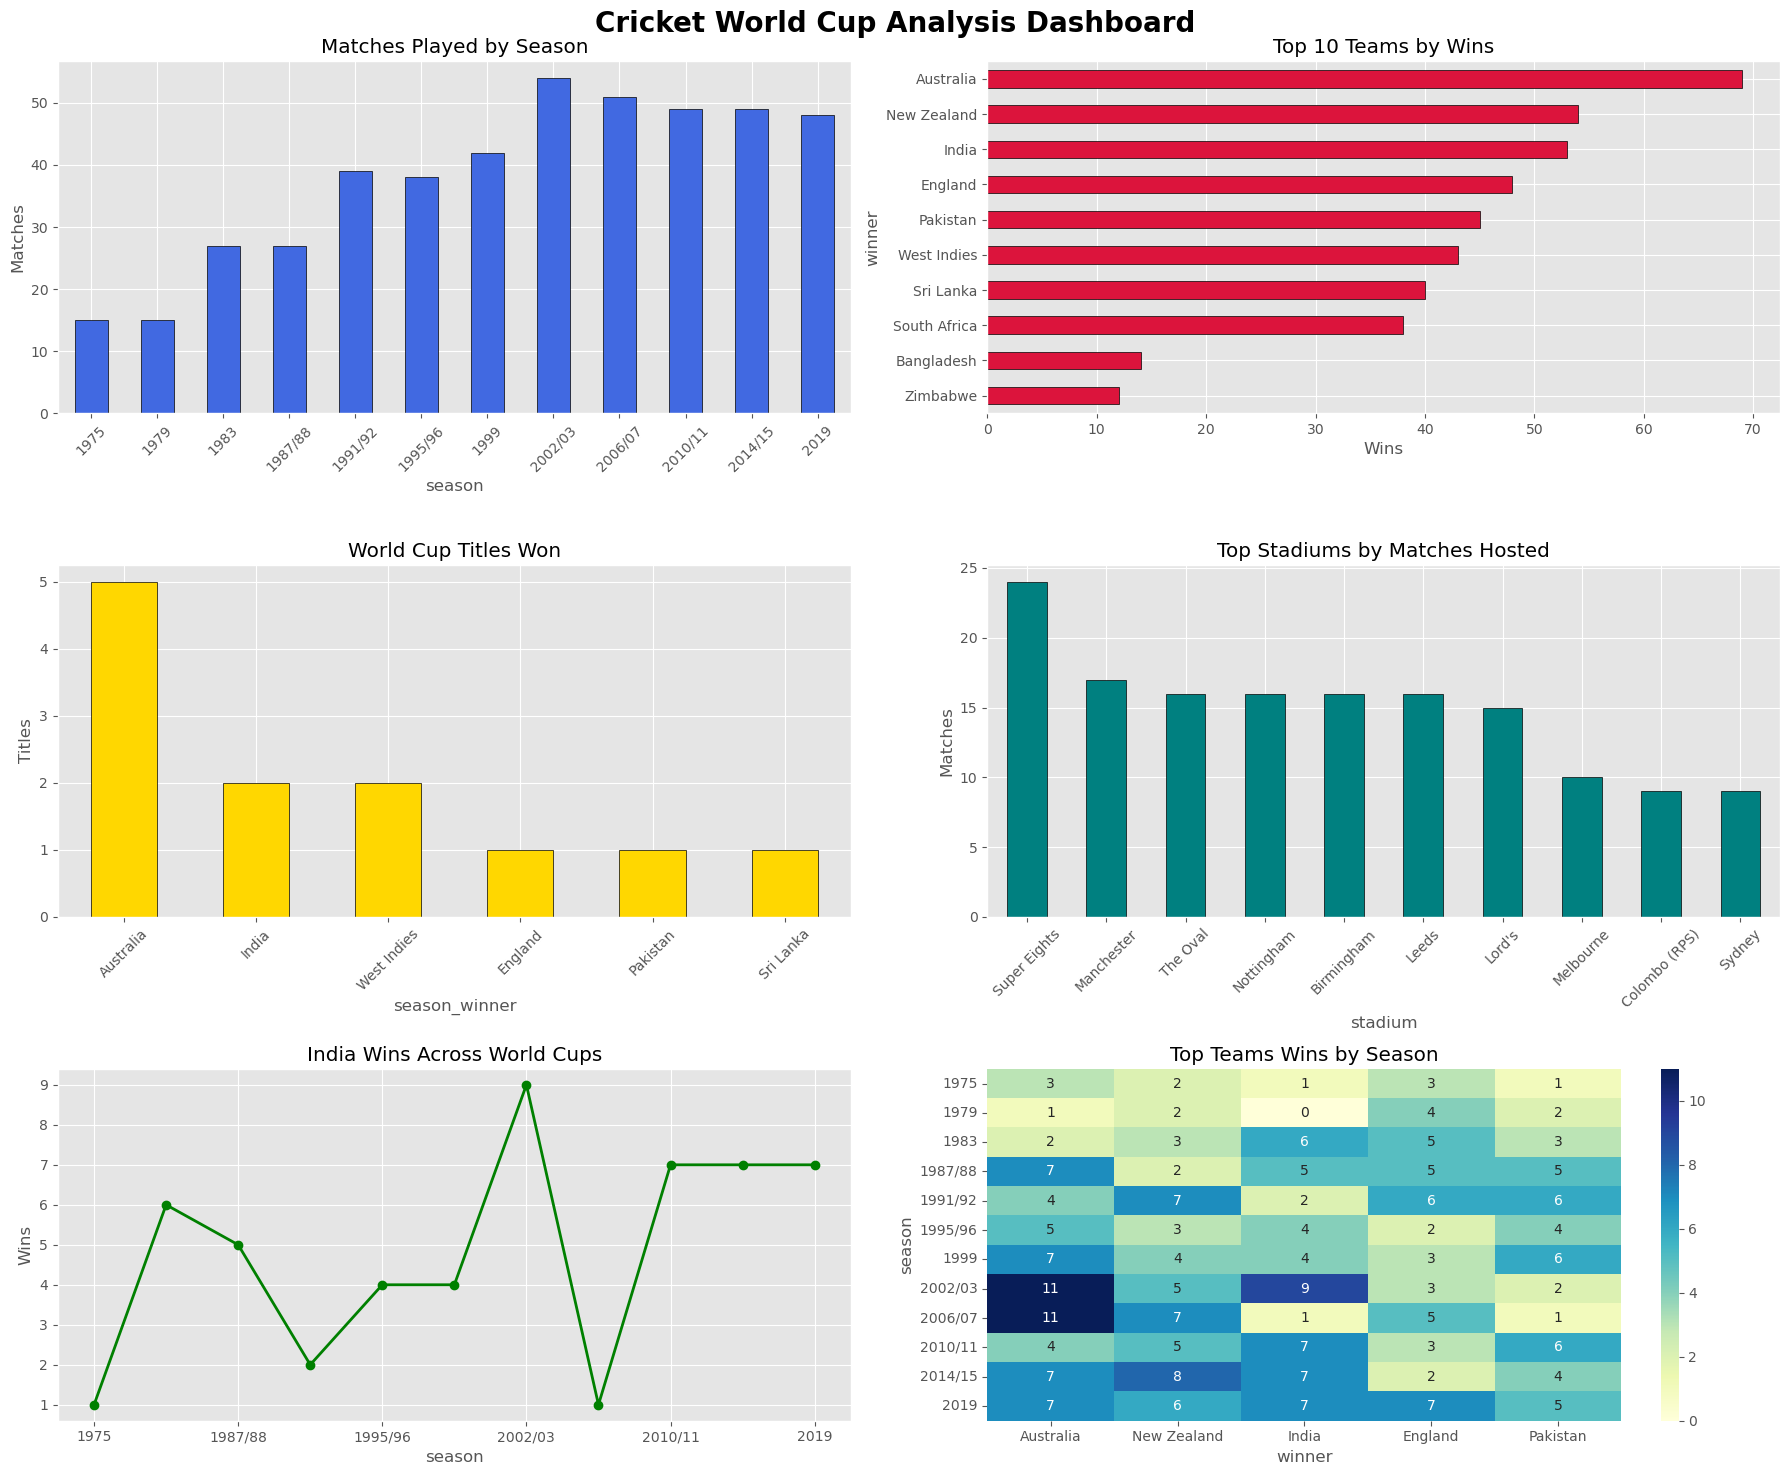

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

fig, axes = plt.subplots(3, 2, figsize=(18, 15))
fig.suptitle(
    'Cricket World Cup Analysis Dashboard',
    fontsize=20,
    fontweight='bold'
)

# ===============================
# 1. Matches Played by Season
# ===============================

season_matches = worldcup.groupby('season').size()

season_matches.plot(
    kind='bar',
    ax=axes[0,0],
    color='royalblue',
    edgecolor='black'
)

axes[0,0].set_title('Matches Played by Season')
axes[0,0].set_ylabel('Matches')
axes[0,0].tick_params(axis='x', rotation=45)

# ===============================
# 2. Top Teams by Wins
# ===============================

wins = worldcup[
    ~worldcup['winner'].isin([
        'No result',
        'Match tied',
        'Match abandoned without a ball bowled'
    ])
]['winner'].value_counts().head(10)

wins.sort_values().plot(
    kind='barh',
    ax=axes[0,1],
    color='crimson',
    edgecolor='black'
)

axes[0,1].set_title('Top 10 Teams by Wins')
axes[0,1].set_xlabel('Wins')

# ===============================
# 3. World Cup Titles Won
# ===============================

titles = worldcup[['season','season_winner']].drop_duplicates()

titles['season_winner'].value_counts().plot(
    kind='bar',
    ax=axes[1,0],
    color='gold',
    edgecolor='black'
)

axes[1,0].set_title('World Cup Titles Won')
axes[1,0].set_ylabel('Titles')
axes[1,0].tick_params(axis='x', rotation=45)

# ===============================
# 4. Top Stadiums
# ===============================

stadiums = worldcup['stadium'].value_counts().head(10)

stadiums.plot(
    kind='bar',
    ax=axes[1,1],
    color='teal',
    edgecolor='black'
)

axes[1,1].set_title('Top Stadiums by Matches Hosted')
axes[1,1].set_ylabel('Matches')
axes[1,1].tick_params(axis='x', rotation=45)

# ===============================
# 5. India Performance
# ===============================

india_matches = worldcup[
    (worldcup['team_1'] == 'India') |
    (worldcup['team_2'] == 'India')
]

india_wins = (
    india_matches[india_matches['winner'] == 'India']
    .groupby('season')
    .size()
)

india_wins.plot(
    marker='o',
    linewidth=2,
    ax=axes[2,0],
    color='green'
)

axes[2,0].set_title('India Wins Across World Cups')
axes[2,0].set_ylabel('Wins')
axes[2,0].grid(True)

# ===============================
# 6. Team Wins Heatmap
# ===============================

top_teams = worldcup['winner'].value_counts().head(5).index

heat_data = pd.crosstab(
    worldcup['season'],
    worldcup['winner']
)[top_teams]

sns.heatmap(
    heat_data,
    annot=True,
    cmap='YlGnBu',
    fmt='d',
    ax=axes[2,1]
)

axes[2,1].set_title('Top Teams Wins by Season')

plt.tight_layout()
plt.show()

# 📊 1. Matches Played by Season

### 🔍 Key Insights

✅ The number of matches played in World Cup tournaments has generally increased over time.

✅ Recent tournaments feature more matches due to the expansion of participating teams and tournament formats.

✅ The steady growth in match count reflects the global popularity and development of cricket.

### 🎯 Conclusion

The World Cup has evolved from a relatively small competition into a large international tournament with greater participation and more competitive fixtures.

---

# 🏆 2. Top 10 Teams by Wins

### 🔍 Key Insights

✅ A small group of teams accounts for the majority of World Cup victories.

✅ Teams at the top have maintained strong performance across multiple tournament editions.

✅ Higher win counts indicate consistency, experience, and long-term competitiveness.

### 🎯 Conclusion

The chart highlights the dominance of established cricketing nations and their continued success in World Cup history.

---

# 🌟 3. World Cup Titles Won

### 🔍 Key Insights

✅ World Cup championships are concentrated among a few nations.

✅ Winning a title requires sustained excellence throughout the tournament.

✅ Some teams have frequently reached advanced stages but secured fewer championships.

### 🎯 Conclusion

A team's total World Cup titles represent its ability to convert strong performances into ultimate tournament success.

---

# 🏟️ 4. Top Stadiums by Matches Hosted

### 🔍 Key Insights

✅ Certain stadiums have hosted significantly more World Cup matches than others.

✅ Major cricket venues continue to be preferred due to their infrastructure and capacity.

✅ A small number of stadiums play a crucial role in World Cup tournaments.

### 🎯 Conclusion

These stadiums have become iconic venues in cricket history and remain important locations for major international events.

---

# 🇮🇳 5. India Wins Across World Cups

### 🔍 Key Insights

✅ India's performance has shown both highs and lows across different World Cup editions.

✅ Several tournaments recorded strong winning campaigns.

✅ The trend demonstrates India's long-standing competitiveness in international cricket.

### 🎯 Conclusion

India has consistently remained one of the strongest teams in World Cup cricket, achieving success across multiple generations.

---

# 🔥 6. Team Wins by Season (Heatmap)

### 🔍 Key Insights

✅ The heatmap reveals how team performance varies from one World Cup season to another.

✅ Darker cells represent seasons with higher win totals.

✅ Some teams display long-term consistency, while others peak during specific tournaments.

### 🎯 Conclusion

The heatmap provides a comprehensive view of team dominance, performance patterns, and historical competitiveness across World Cup seasons.

---

# 📌 Overall Findings

### 🚀 Major Observations

✅ The Cricket World Cup has grown significantly over the years.

✅ A small number of nations have historically dominated both match victories and championship titles.

✅ Certain stadiums have become central venues for hosting prestigious World Cup matches.

✅ Team performances vary across tournaments, demonstrating the competitive nature of international cricket.

✅ India and other leading nations have maintained strong performances over multiple World Cup editions.

---

# 🎯 Final Conclusion

The analysis demonstrates the evolution and growth of the Cricket World Cup as one of the world's premier sporting events. Historical data reveals patterns of team dominance, tournament expansion, venue importance, and performance consistency. These insights provide a deeper understanding of how the World Cup has developed over time and highlight the teams and venues that have shaped its rich history.


## 📋 Project Summary

---

### 🎯 Project Objective

The primary objective of this project was to analyze historical Cricket World Cup data and uncover meaningful insights related to team performance, tournament growth, venue utilization, and championship achievements. Through data visualization and exploratory data analysis, patterns and trends were identified to better understand the evolution of the Cricket World Cup over the years.

---

## 🔍 Key Findings

### 📈 Tournament Growth
- The number of matches played has increased significantly across World Cup editions, reflecting the expansion of tournament formats and greater participation from cricket-playing nations.
- The increasing scale of the tournament demonstrates the growing popularity and global reach of cricket.

### 🏆 Team Performance
- A small group of teams has consistently dominated World Cup competitions through a high number of match victories and championship titles.
- Historical data reveals long-term success and sustained competitiveness among established cricketing nations.

### 🌟 Championship Success
- World Cup titles are concentrated among a limited number of countries, highlighting the challenges associated with achieving tournament success.
- Strong performances throughout both group and knockout stages are essential for winning championships.

### 🏟️ Venue Analysis
- Several stadiums have hosted a substantial number of World Cup matches, making them iconic venues in international cricket.
- These stadiums continue to play an important role due to their infrastructure, experience, and spectator capacity.

### 🇮🇳 India's Performance
- India's performance has shown remarkable consistency across multiple World Cup editions.
- Several tournaments recorded outstanding campaigns, demonstrating India's strong presence and competitiveness in world cricket.

### 🔥 Seasonal Performance Trends
- Team performances vary across different World Cup seasons, highlighting the dynamic and competitive nature of international cricket.
- Heatmap analysis revealed periods of dominance, emerging contenders, and changing competitive landscapes.

---

## 📊 Analytical Techniques Used

✅ Data Cleaning and Preprocessing

✅ Exploratory Data Analysis (EDA)

✅ Bar Charts

✅ Line Charts

✅ Histograms

✅ Heatmaps

✅ Comparative Performance Analysis

✅ Trend Analysis

---

## 💡 Business and Sports Insights

- Consistent participation often contributes to long-term success.
- Championship victories require not only strong teams but also the ability to perform under pressure in critical matches.
- Infrastructure and venue selection play a significant role in organizing successful international tournaments.
- Historical performance trends can support strategic decision-making, sports analytics, and future tournament planning.

---

## 🚀 Final Conclusion

The analysis demonstrates that the Cricket World Cup has evolved into one of the most prestigious sporting events in the world. Over time, the tournament has expanded in size, competitiveness, and global impact. While a few nations have historically dominated the competition, the data also highlights the continuous evolution of teams, venues, and tournament structures.

Through effective use of data visualization and exploratory analysis, this project successfully transformed raw cricket data into actionable insights, providing a comprehensive understanding of World Cup history, team achievements, and tournament development.

---

## ✅ Project Outcome

**This project successfully analyzed Cricket World Cup historical data to identify trends, evaluate team performances, examine tournament growth, and generate data-driven insights through visualization techniques and statistical exploration.** 🏏📊